# FCC-ee HEB V26.2 — native PyWIT impedance model and repository exports

**Production notebook using the installed `fcc_ee_booster_pywit_model.HEBModel`.** The original native PyWIT model computes the real input-based impedance budget and the $\sigma_z=0.4$ mm bunch wakes; this revision adds **versioned, source-auditable exports** for the `v26_2` Git branch.

**RW:** two-layer Cu/NEG Gold/TL, $R_q=0.3\,\mu$m, $q=-2.1043$ (CST-equivalent reference convention), calculated to 10 THz. **Kicker:** integrated 20 m reference scaled to 4.18 m HEB; quadrupolar terms omitted. All other impedances use their original local input files. No CST data or Patrick factor are imported into the calculation.

Data written when `SAVE_PROJECT_DATA=True`:

- `data/elliptic_elements/base_30mm/neg150nm/v26_2_GoldTL_Rq0p3um/`: ring-integrated RW impedance (0–50 GHz **and** 1 kHz–10 THz), RW 0.4 mm wakes.
- `data/kickers/HEB_v26_2_4p18m/`: scaled HEB kicker impedance and 0.4 mm wakes. **The original 20 m source remains untouched.**
- `data/total/v26_2/`: signed total impedances, 0.4 mm total wakes, tracking ECSV, source provenance and optical locations.
- `figures/v26_2/`: six **separate**, filled, positive-only impedance-budget plots, plus the signed wake plots.

**All write targets are new version-specific paths; existing `rf_cavities`, `bpm`, `bellows`, and V26.1 data files are never rewritten.** Numeric files retain signed Re/Im/wake values. The positive-only clipping is for plotting **only**.

Requires the already-installed updated `HEBModel` and your local V26.2 optics, complex RF and kicker sources, and wiggler IW2D/cache. No fixture or synthetic impedance is used.


In [1]:
from pathlib import Path
import json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from fcc_ee_booster_pywit_model import HEBModel
from fcc_ee_booster_pywit_model.package_paths import base_dir

print('Active HEBModel:', HEBModel.__module__)
assert HEBModel.__module__.endswith('.heb_gold_tl'), (
    'Updated native HEBModel not installed. Run install_hebmodel.py against your local package first.')
DATA = Path(base_dir).resolve() / 'data'
PROJECT_ROOT = DATA.parent.parent
print('Local data directory:', DATA)
print('Git project root:', PROJECT_ROOT)
assert (DATA/'rf_cavities').is_dir() and (DATA/'bpm').is_dir(), 'Local project data/ not found.'


Active HEBModel: fcc_ee_booster_pywit_model.heb_gold_tl
Local data directory: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data
Git project root: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model


## 1 · Local V26.2 configuration and output destinations

Set your **existing local paths** as needed. `SAVE_PROJECT_DATA=True` and `SAVE_FIGURES=True` save the new results into your `v26_2` branch's **versioned folders**. Re-running updates files inside these *new folders only*; original source data is untouched.


In [2]:
# LOCAL INPUTS — these are paths inside your installed/local project.
OPTICS_TFS = DATA / 'optics' / 'v26_2' / 'heb_ring_z.tfs'
KICKER_ARCHIVE = None  # Auto-locate data/kickers/Z_*_optimizedKicker.txt or kicker_z_w.zip
WIGGLER_CACHE = None   # Validated flat-chamber IW2D cache, if available
FLATCHAMBER_EXE = None # Or explicit path to flatchamber.x
ENERGY_EV = 20e9

# REPOSITORY EXPORT SWITCHES
SAVE_PROJECT_DATA = True         # New RW, HEB kicker, and total files in data/...
SAVE_FIGURES = True              # Figures in <git-root>/figures/v26_2/
REPLACE_V26_2_EXPORTS = True     # Re-running may refresh ONLY the versioned folders below
SAVE_RW_HIGH_FREQUENCY = True    # Export computed Gold/TL RW from 1 kHz to 10 THz

# Save paths are derived from this installed package; they do NOT depend on VS Code cwd.
RW_EXPORT_DIR = DATA / 'elliptic_elements' / 'base_30mm' / 'neg150nm' / 'v26_2_GoldTL_Rq0p3um'
KICKER_EXPORT_DIR = DATA / 'kickers' / 'HEB_v26_2_4p18m'
TOTAL_EXPORT_DIR = DATA / 'total' / 'v26_2'
FIGURES_DIR = PROJECT_ROOT / 'figures' / 'v26_2'
OUTPUT = Path(base_dir) / 'outputs' / 'V26_2_GoldTL_Rq0p3um_kicker4p18m'  # Optional scratch directory

# Refuse repository exports into a regular site-packages installation.
# This project must be imported from YOUR Git clone (editable installation).
if SAVE_PROJECT_DATA and not (PROJECT_ROOT/'.git').exists():
    raise RuntimeError(
        'HEBModel was not imported from a Git checkout: ' + str(PROJECT_ROOT) + '\n'
        'Open the local fcc_ee_booster_pywit_model clone and install it in editable mode '
        '(python -m pip install -e .), then restart the notebook kernel.'
    )

print('V26.2 optics:', OPTICS_TFS)
print('Complex RF longitudinal input:', DATA/'rf_cavities'/'Z_single_rf_cavity_long_filter_3mm.txt')
print('Kicker source directory:', DATA/'kickers')
print('Export RW:', RW_EXPORT_DIR)
print('Export HEB kicker:', KICKER_EXPORT_DIR)
print('Export total:', TOTAL_EXPORT_DIR)
print('Save figures:', FIGURES_DIR)
if not OPTICS_TFS.is_file():
    raise FileNotFoundError(f'LOCAL V26.2 TFS not found: {OPTICS_TFS}. Set OPTICS_TFS to its real path.')


V26.2 optics: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/optics/v26_2/heb_ring_z.tfs
Complex RF longitudinal input: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_single_rf_cavity_long_filter_3mm.txt
Kicker source directory: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers
Export RW: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/elliptic_elements/base_30mm/neg150nm/v26_2_GoldTL_Rq0p3um
Export HEB kicker: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/HEB_v26_2_4p18m
Export total: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/total/v26_2
Save figures: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/figures/v26_2


## 2 · Build the **real** HEBModel

In [3]:
model = HEBModel(
    energy=ENERGY_EV,
    optics_filename=OPTICS_TFS,
    n_rf=112,
    rf_name_hint='ac800',
    sigma_cu=5.8e7,
    sigma_neg=1e6,
    neg_t_m=150e-9,
    roughness_rq_m=0.3e-6,
    gold_reference_q=-2.1043,
    beam_pipe_radius_m=0.030,
    rw_fmax_hz=10e12,
    rw_nfreq=2801,
    kicker_length_m=4.18,
    kicker_reference_length_m=20.0,
    kicker_archive=KICKER_ARCHIVE,
    wigglers=10,
    wiggler_each_length_m=6.03,
    wiggler_beta_m=4.0,
    wiggler_cache=WIGGLER_CACHE,
    wiggler_iw2d_executable=FLATCHAMBER_EXE,
    n_bellows=10000,
    bellows_length_m=0.15,
)
assert len(model.elements)==6
print('Native PyWIT elements:', [(e.name, len(e.components)) for e in model.elements])
print('Kicker 4.18/20 =', model.kicker_factor)
print('BPMs', model.n_bpm, 'RF', model.n_rf, 'RW length m', model.rw_length_m)
model.inventory

Native PyWIT elements: [('RW', 3), ('Wiggler', 3), ('Kicker', 3), ('RF', 3), ('BPM', 3), ('Bellows', 3)]
Kicker 4.18/20 = 0.209
BPMs 2740 RF 112 RW length m 89080.35599996046


,component,count,physical_length_m,location_status
0,RW,1,89080.356,"distributed in ring (excludes bellows, wiggler..."
1,Wiggler,10,60.300,provisional symmetric S4; target beta 4 m
2,Kicker,10,4.180,ring-average (provisional; kicker s not supplied)
3,RF,112,NaN,named V26.2 ac800 cavities
4,BPM,2740,NaN,named V26.2 BPMs
5,Bellows,10000,1500.000,positions not available; source already ring i...


## 3 · Check every imported source file and beta normalization

In [4]:
# No copied historic results. Every component must identify its input file or analytic calculation.
with pd.option_context('display.max_colwidth', 100):
    display(model.source_provenance)
for key, table in model.locations.items():
    print(f'{key}: {len(table)} positions')
print('Reference beta x/y [m]:', model.beta_x_avg, model.beta_y_avg)
print('RF transverse beta weights:', model.rf_beta_factor_x, model.rf_beta_factor_y)
print('BPM transverse beta weights:', model.bpm_beta_factor_x, model.bpm_beta_factor_y)

,family,plane,path,normalization,multiplier,input_fmax_ghz
0,RF,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_s...,"single element, location-beta weighted",112.000000,50.00000
1,RF,x,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_s...,"single element, location-beta weighted",181.792255,50.00000
2,RF,y,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_s...,"single element, location-beta weighted",172.122502,50.00000
3,BPM,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bpm/Z_bpm_long_...,"single element, location-beta weighted",2740.000000,50.00000
4,BPM,x,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bpm/Z_bpm_dipx_...,"single element, location-beta weighted",2989.225364,50.00000
5,BPM,y,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bpm/Z_bpm_dipy_...,"single element, location-beta weighted",2943.036183,50.00000
6,Bellows,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bellows/Z_bello...,already integrated complete ring; NO extra count,1.000000,50.00000
7,Bellows,x,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bellows/Z_bello...,already integrated complete ring; NO extra count,1.000000,50.00000
8,Bellows,y,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bellows/Z_bello...,already integrated complete ring; NO extra count,1.000000,50.00000
9,Kicker,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/Z_long_...,"20 m source, scaled once to 4.18 m HEB system; local beta provisional",0.209000,49.99593


RF: 112 positions
BPM: 2740 positions
Wiggler: 10 positions
Kicker: 0 positions
Reference beta x/y [m]: 58.58244272744051 68.97300253394677
RF transverse beta weights: 181.79225490742525 172.1225022574451
BPM transverse beta weights: 2989.225364033652 2943.03618331163


## 4 · Full signed impedance budget (PyWIT total; 0–50 GHz)

Values remain **signed and unmodified** in memory and in the exported numerical tables. The **separate filled** presentation plots show only positive values $\geq 10^0$, as requested.


In [5]:
budget = model.impedance_budget(np.linspace(0, 50e9, 5001), validate_total=True)
assert set(budget) == {'long', 'x', 'y'}
for plane, tab in budget.items():
    component_sum = sum(tab[f'Re_{family}'].to_numpy() + 1j*tab[f'Im_{family}'].to_numpy()
                        for family in ('RW','Wiggler','Kicker','RF','BPM','Bellows'))
    total = tab['Re_Total'].to_numpy() + 1j*tab['Im_Total'].to_numpy()
    np.testing.assert_allclose(total, component_sum, rtol=1e-8, atol=1e-8)
    print(f'{plane}: {len(tab)} frequency rows; PyWIT component sum verified')
print('Native PyWIT total at 1 GHz:',
      model.total.get_component('z0000').impedance(np.array([1e9])))


long: 5001 frequency rows; PyWIT component sum verified
x: 5001 frequency rows; PyWIT component sum verified
y: 5001 frequency rows; PyWIT component sum verified
Native PyWIT total at 1 GHz: [73970.31984547+1420.79647851j]


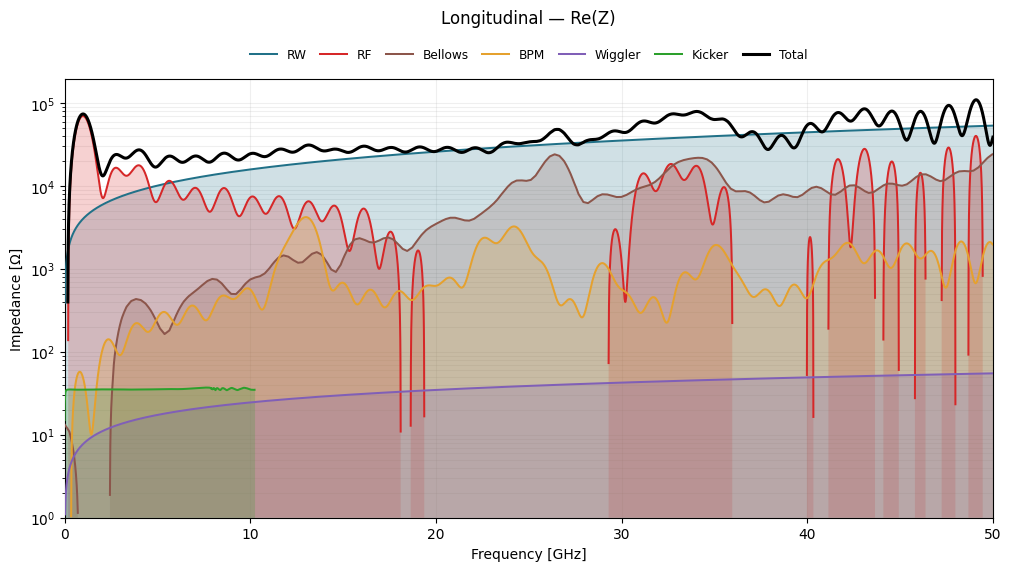

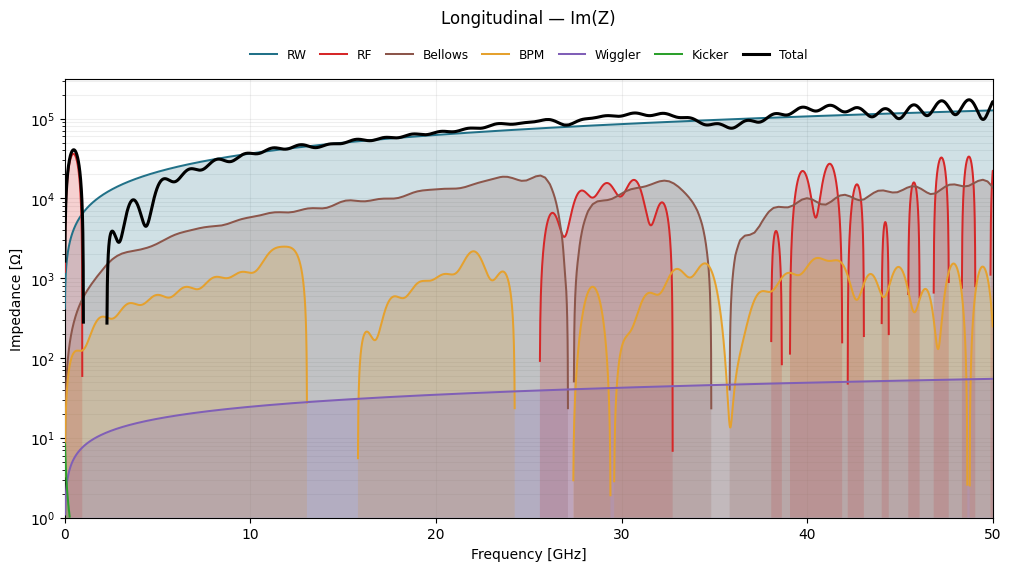

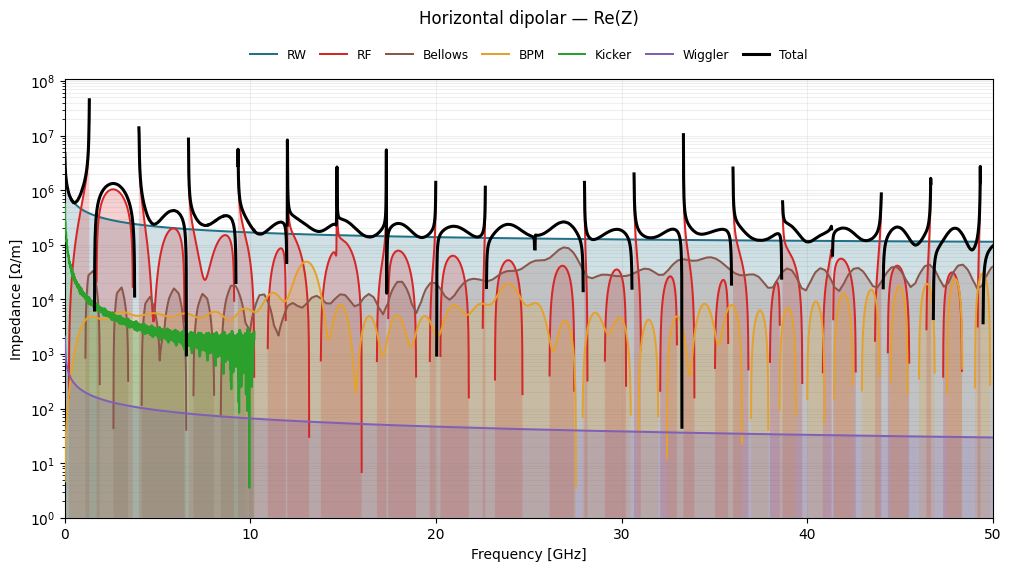

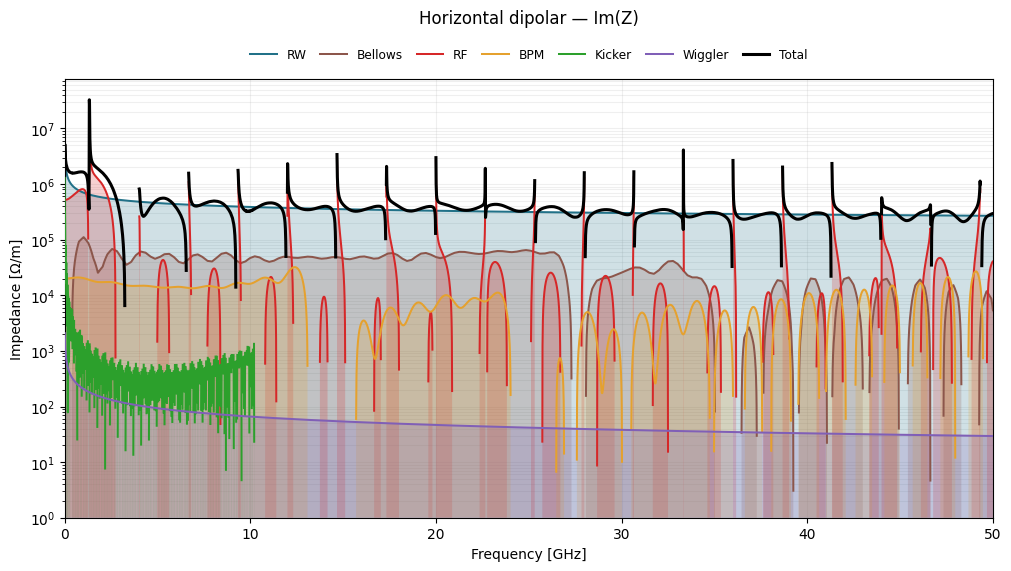

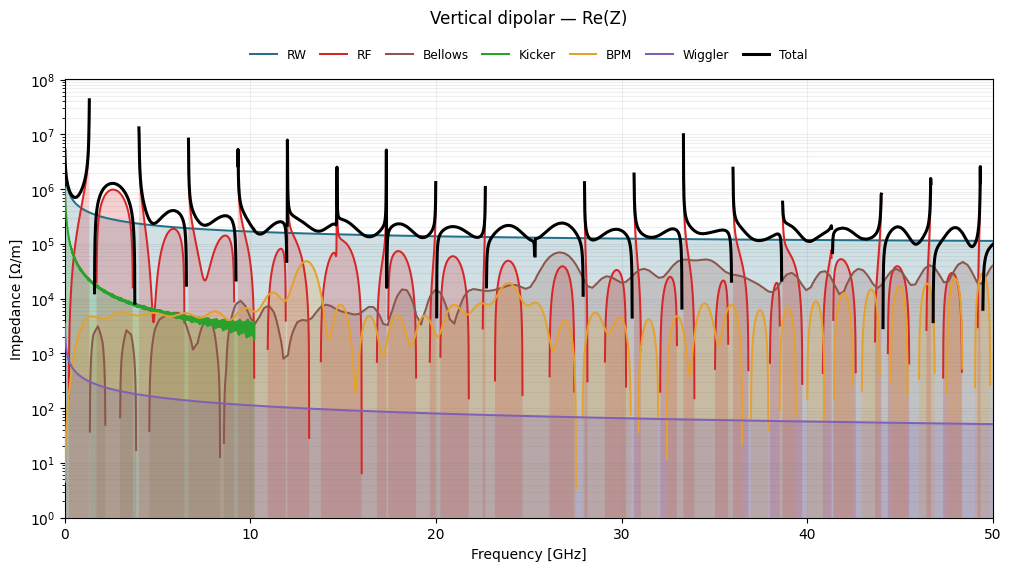

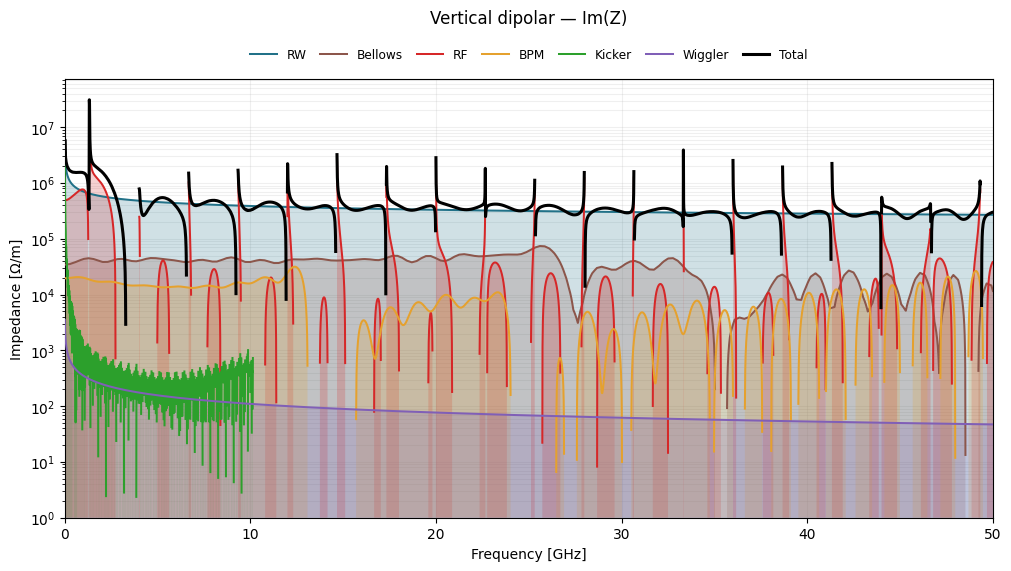

In [6]:
# Six SEPARATE filled budget figures; larger positive components first, smaller last.
# Signed numerical data is NEVER clipped or converted to abs(): only the display is masked.
colors = {
    'RW':'#217188',        # deep teal-blue
    'Wiggler':'#805fb7',   # purple
    'Kicker':'#2ca02c',    # green — distinct from RF
    'RF':'#d62728',        # red
    'BPM':'#e5a12e',       # amber
    'Bellows':'#8c564b',   # brown
}
families = tuple(colors)
plane_labels = {'long':'Longitudinal','x':'Horizontal dipolar','y':'Vertical dipolar'}
plane_files = {'long':'long','x':'dipx','y':'dipy'}

def positive_for_plot(y, floor=1.0):
    arr = np.asarray(y, float)
    return np.where(np.isfinite(arr) & (arr >= floor), arr, np.nan)

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)

for plane in ('long','x','y'):
    tab = budget[plane]
    freq = tab.frequency_GHz.to_numpy(float)
    for part in ('Re','Im'):
        # Rank the physically positive displayed values by median; small curves are drawn last.
        scores = {}
        for family in families:
            a = positive_for_plot(tab[f'{part}_{family}'])
            scores[family] = float(np.nanmedian(a)) if np.any(np.isfinite(a)) else -np.inf
        order = sorted(families, key=lambda family: scores[family], reverse=True)

        fig, ax = plt.subplots(figsize=(10,5.6), layout='constrained')
        for family in order:
            y = positive_for_plot(tab[f'{part}_{family}'])
            if not np.any(np.isfinite(y)):
                continue
            ax.fill_between(freq, 1.0, y, color=colors[family], alpha=0.21,
                            linewidth=0, zorder=2)
            ax.plot(freq, y, color=colors[family], linewidth=1.45,
                    label=family, zorder=3)
        total = positive_for_plot(tab[f'{part}_Total'])
        ax.plot(freq, total, color='black', linewidth=2.2, label='Total', zorder=50)
        ax.set(xlim=(0,50), xlabel='Frequency [GHz]',
               ylabel=('Impedance [Ω]' if plane=='long' else 'Impedance [Ω/m]'),
               title=f'{plane_labels[plane]} — {part}(Z)')
        ax.set_yscale('log')
        ax.set_ylim(bottom=1.0)
        ax.grid(alpha=.20, which='both')
        # Place legend outside the data area; do not obscure large RF/RW peaks.
        ax.legend(ncol=7, fontsize=8.7, frameon=False, loc='lower center',
                  bbox_to_anchor=(0.5,1.015), columnspacing=1.15, handlelength=2.2)
        ax.set_title(f'{plane_labels[plane]} — {part}(Z)', pad=40)
        if SAVE_FIGURES:
            fig.savefig(FIGURES_DIR/f'z_{plane_files[plane]}_{part.lower()}_total_v26_2.png',
                        dpi=180, bbox_inches='tight')
        plt.show()
        plt.close(fig)


## 5 · $\sigma_z=0.4$ mm bunch wakes (RW computed to 10 THz)

The underlying `HEBModel` method calculates the wake from the **full complex impedance**, with the high-frequency Gold/TL RW and the original numerical bandwidth of each other component. These signed values are what will be exported to `data/` and the PyHEADTAIL tracking file.


long: 1535 points; wake component sum verified
x: 1535 points; wake component sum verified
y: 1535 points; wake component sum verified


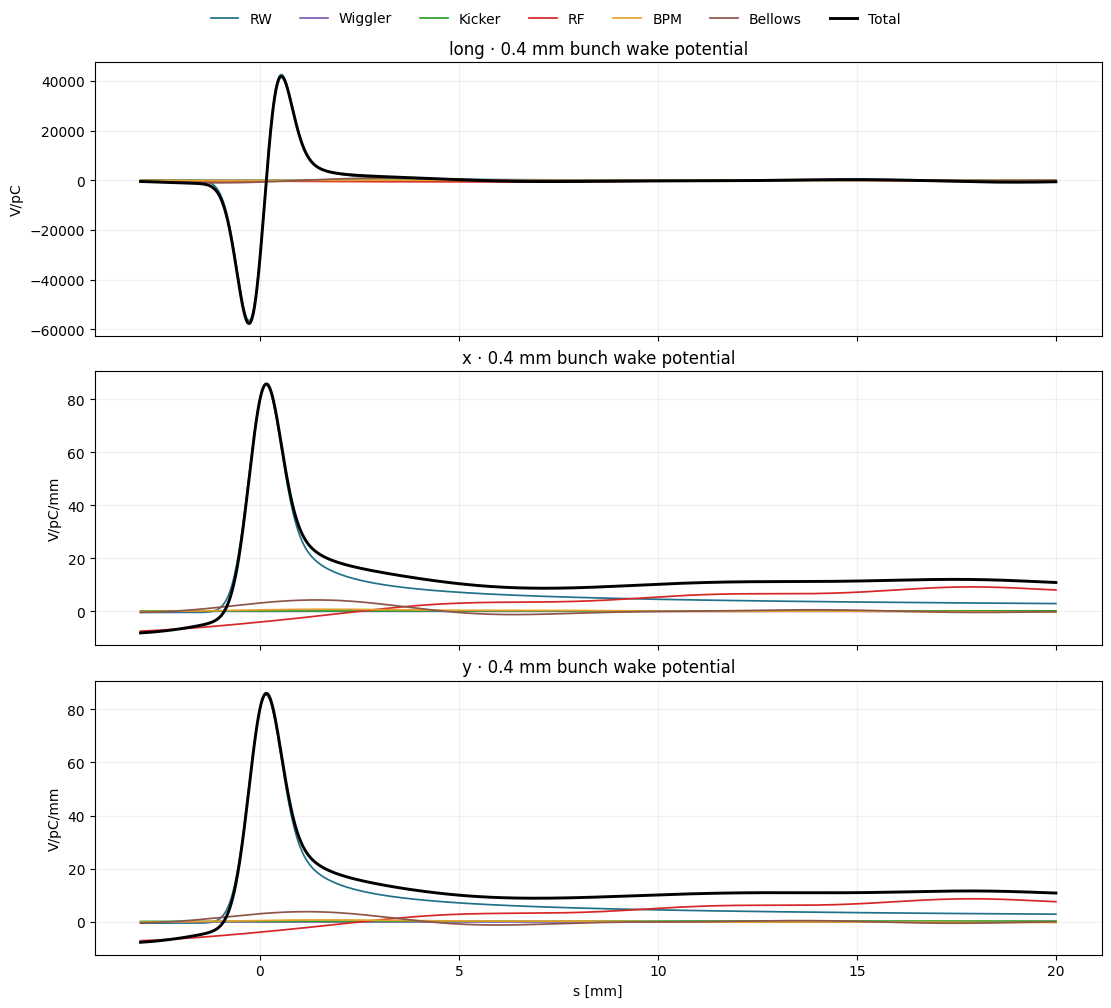

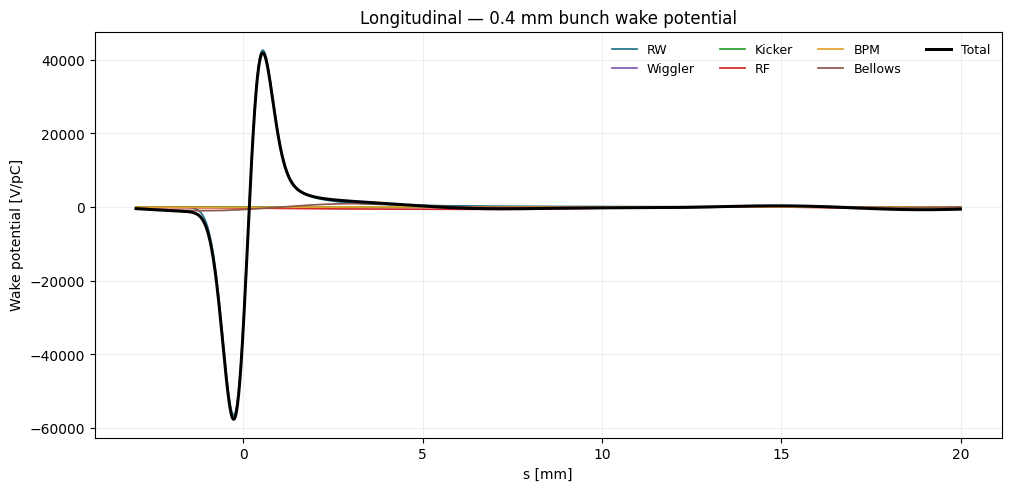

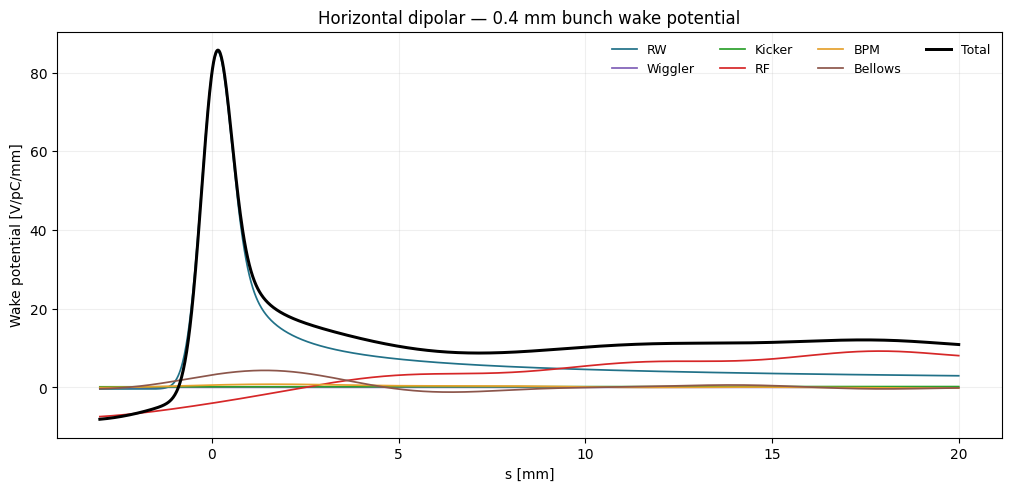

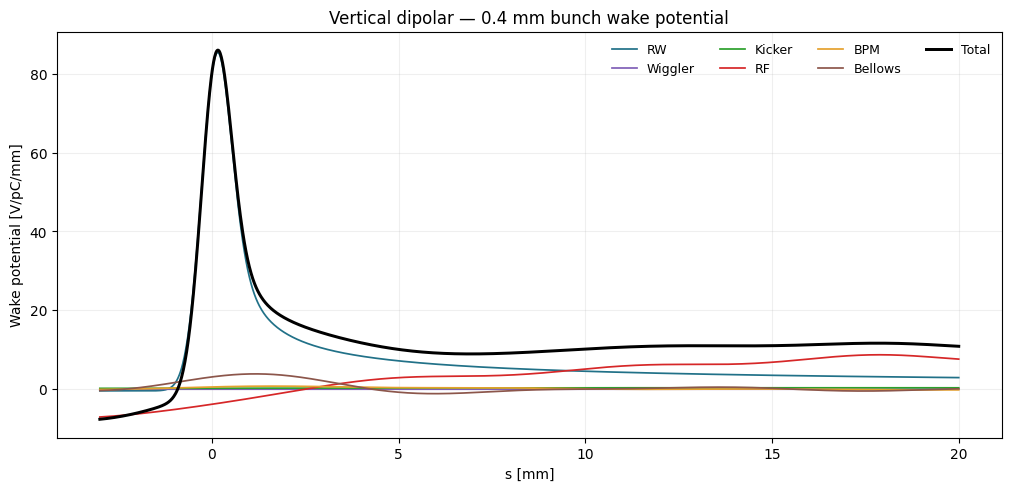

In [7]:
wakes = model.bunch_wake_04mm(sigma_z_m=0.4e-3, fmax_hz=10e12,
                              df_hz=100e6, s_window_mm=(-3,20))
for plane in ('long','x','y'):
    w = wakes[plane]
    component_sum = sum(w[family].to_numpy(float) for family in families)
    np.testing.assert_allclose(w.Total.to_numpy(float), component_sum, rtol=1e-7, atol=1e-7)
    print(f'{plane}: {len(w)} points; wake component sum verified')

fig, ax = plt.subplots(3,1,figsize=(11,10),sharex=True,layout='constrained')
for idx, plane in enumerate(('long','x','y')):
    table = wakes[plane]
    for family, color in colors.items():
        ax[idx].plot(table.s_mm,table[family],lw=1.25,color=color,label=family)
    ax[idx].plot(table.s_mm,table.Total,color='black',lw=2.1,label='Total')
    ax[idx].set_ylabel('V/pC' if plane=='long' else 'V/pC/mm')
    ax[idx].set_title(f'{plane} · 0.4 mm bunch wake potential')
    ax[idx].grid(alpha=.18)
ax[-1].set_xlabel('s [mm]')
h, labels = ax[0].get_legend_handles_labels()
fig.legend(h,labels,ncol=7,loc='outside upper center',frameon=False)
if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR/'wake_total_0p4mm_v26_2.png',dpi=180,bbox_inches='tight')
plt.show()
plt.close(fig)

# Additional single-plane wake figures are useful for talks/reviews.
for plane in ('long','x','y'):
    tab = wakes[plane]
    fig, ax = plt.subplots(figsize=(10,4.8),layout='constrained')
    for family,color in colors.items():
        ax.plot(tab.s_mm,tab[family],lw=1.25,color=color,label=family)
    ax.plot(tab.s_mm,tab.Total,color='black',lw=2.15,label='Total')
    ax.set(xlabel='s [mm]',
           ylabel=('Wake potential [V/pC]' if plane=='long' else 'Wake potential [V/pC/mm]'),
           title=f'{plane_labels[plane]} — 0.4 mm bunch wake potential')
    ax.grid(alpha=.2)
    ax.legend(ncol=4,frameon=False,fontsize=9)
    if SAVE_FIGURES:
        fig.savefig(FIGURES_DIR/f'wake_{plane_files[plane]}_0p4mm_v26_2.png',
                    dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 6 · Export the new V26.2 impedance, wake and tracking files

The **existing source directories** (`rf_cavities/`, `bpm/`, `bellows/`, the original kicker and V26.1 RW files) are untouched. This cell creates versioned RW/kicker/total folders **from the freshly computed `model`, `budget`, and `wakes` above**.

All impedance files follow the current project convention: `frequency_GHz, Re(Z), Im(Z)`; wakes use `s_mm, wake_potential`. They are *ring-integrated and beta weighted once* (including the 4.18/20 kicker length ratio); do **not** multiply by device counts again. Presentation plots mask negative values, but these exported arrays retain the full signed response.


In [8]:
# ============================================================
# V26.2 REPOSITORY DATA EXPORT — from the native PyWIT HEBModel
# ============================================================
from scipy.constants import c as speed_of_light

plane_stems = {'long':'long', 'x':'dipx', 'y':'dipy'}
write_roots = {'RW':RW_EXPORT_DIR, 'Kicker':KICKER_EXPORT_DIR, 'Total':TOTAL_EXPORT_DIR}

# Safety: write ONLY inside the three V26.2 export subdirectories.
for group, path in write_roots.items():
    assert 'v26_2' in str(path).lower(), f'Not a V26.2 export path: {path}'
    assert DATA.resolve() in path.resolve().parents, f'Export escapes package data/: {path}'
assert (DATA/'rf_cavities').resolve() not in [p.resolve() for p in write_roots.values()]

# Prevent silently publishing mislabeled files if physical settings are changed later.
for value, expected, label in ((model.kicker_length_m, 4.18, 'HEB kicker length [m]'),
                              (model.kicker_reference_length_m, 20.0, 'kicker reference length [m]'),
                              (model.rq_m, 0.3e-6, 'RW roughness RMS [m]'),
                              (model.neg_t_m, 150e-9, 'NEG thickness [m]')):
    if not np.isclose(float(value),expected,rtol=1e-10,atol=0):
        raise ValueError(f'{label} changed from {expected}; rename versioned export directory/files first')

saved_files = []
def _can_write(path, expected_root):
    path, expected_root = Path(path).resolve(), Path(expected_root).resolve()
    if expected_root not in path.parents:
        raise ValueError(f'Refusing to write outside V26.2 export root: {path}')
    if path.exists() and not REPLACE_V26_2_EXPORTS:
        raise FileExistsError(f'V26.2 file exists: {path}; enable REPLACE_V26_2_EXPORTS to refresh it')
    path.parent.mkdir(parents=True, exist_ok=True)
    return path

def write_impedance(path, freq_hz, z, root, description, units):
    f = np.asarray(freq_hz,dtype=float)
    z = np.asarray(z,dtype=complex)
    if len(f)!=len(z) or len(f)<3 or not np.all(np.diff(f)>0):
        raise ValueError(f'Impedance table has invalid frequency grid: {path}')
    if not np.all(np.isfinite(z)):
        raise ValueError(f'Non-finite complex impedance: {path}')
    path = _can_write(path,root)
    rows = np.column_stack((f/1e9, z.real, z.imag))
    np.savetxt(path, rows, fmt='%.14e',
               header=(description + '\n' +
                       f'Freq(GHz) Re(Z)[{units}] Im(Z)[{units}]'))
    # Round-trip the file to ensure that all three columns can be read by PyWIT.
    check = np.loadtxt(path,comments='#',ndmin=2)
    np.testing.assert_allclose(check,rows,rtol=5e-13,atol=1e-13)
    saved_files.append(path)

def write_wake(path, s_mm, potential, root, description, units):
    s = np.asarray(s_mm,dtype=float)
    w = np.asarray(potential,dtype=float)
    if len(s)!=len(w) or len(s)<3 or not np.all(np.diff(s)>0):
        raise ValueError(f'Wake coordinate grid invalid: {path}')
    if not np.all(np.isfinite(w)):
        raise ValueError(f'Non-finite wake values: {path}')
    path = _can_write(path,root)
    rows = np.column_stack((s,w))
    np.savetxt(path, rows, fmt='%.14e',
               header=description + '\n' + f's(mm) WakePotential[{units}]')
    check = np.loadtxt(path,comments='#',ndmin=2)
    np.testing.assert_allclose(check,rows,rtol=5e-13,atol=1e-13)
    saved_files.append(path)

def save_csv(table,filename,root):
    path = _can_write(root/filename,root)
    table.to_csv(path,index=False)
    saved_files.append(path)

if SAVE_PROJECT_DATA:
    for folder in write_roots.values():
        folder.mkdir(parents=True, exist_ok=True)

    rw_grid_hi = np.asarray(model._rw_log_grid,dtype=float)  # native Gold/TL grid, up to 10 THz
    assert rw_grid_hi[-1] >= 9.99e12, 'High-frequency RW grid does not extend to 10 THz'
    for plane in ('long','x','y'):
        stem = plane_stems[plane]
        table = budget[plane]
        f_50 = table.frequency_GHz.to_numpy(float)*1e9
        unit = 'Ohm' if plane=='long' else 'Ohm_per_m'
        rw_50 = np.asarray(model.component_impedance('RW',plane,f_50),complex)
        kicker_50 = np.asarray(model.component_impedance('Kicker',plane,f_50),complex)
        total_50 = table[f'Re_Total'].to_numpy() + 1j*table[f'Im_Total'].to_numpy()
        np.testing.assert_allclose(rw_50.real,table['Re_RW'],rtol=1e-10,atol=1e-9)
        np.testing.assert_allclose(kicker_50.imag,table['Im_Kicker'],rtol=1e-10,atol=1e-9)
        write_impedance(RW_EXPORT_DIR/f'Z_{stem}_RW_GoldTL_Rq0p3um_v26_2.txt',
                        f_50,rw_50,RW_EXPORT_DIR,
                        'V26.2 ring-integrated Gold/TL NEG150nm/Cu RW; Rq=0.3um; q=-2.1043; NOT per metre',unit)
        if SAVE_RW_HIGH_FREQUENCY:
            rw_hi = np.asarray(model.component_impedance('RW',plane,rw_grid_hi),complex)
            write_impedance(RW_EXPORT_DIR/f'Z_{stem}_RW_GoldTL_Rq0p3um_high_10THz_v26_2.txt',
                            rw_grid_hi,rw_hi,RW_EXPORT_DIR,
                            'V26.2 ring-integrated RW; native logarithmic 1kHz–10THz Gold/TL grid',unit)
        write_impedance(KICKER_EXPORT_DIR/f'Z_{stem}_optimizedKicker_HEB_4p18m_v26_2.txt',
                        f_50,kicker_50,KICKER_EXPORT_DIR,
                        'V26.2 HEB integrated kicker, original collider 20m source × (4.18/20) once; x/y beta provisional; zero beyond source bandwidth',unit)
        total_filename = (f'Z_total_{stem}_v26_2.txt' if plane=='long'
                          else f'Z_total_{stem}_beta_weighted_v26_2.txt')
        write_impedance(TOTAL_EXPORT_DIR/total_filename,
                        f_50,total_50,TOTAL_EXPORT_DIR,
                        'V26.2 native PyWIT full-ring total; one normalization per component; 0–50GHz',unit)

        s_mm = wakes[plane].s_mm.to_numpy(float)
        wu = 'V_per_pC' if plane=='long' else 'V_per_pC_per_mm'
        write_wake(RW_EXPORT_DIR/f'W_{stem}_RW_GoldTL_sigma0p4mm_v26_2.txt',
                   s_mm,wakes[plane]['RW'],RW_EXPORT_DIR,
                   'V26.2 ring-integrated Gold/TL RW 0.4mm Gaussian bunch wake; RW to 10THz',wu)
        write_wake(KICKER_EXPORT_DIR/f'W_{stem}_optimizedKicker_HEB_4p18m_sigma0p4mm_v26_2.txt',
                   s_mm,wakes[plane]['Kicker'],KICKER_EXPORT_DIR,
                   'V26.2 HEB kicker 0.4mm wake; band-limited by actual supplied kicker spectrum',wu)
        total_wake_filename = (f'W_total_{stem}_sigma0p4mm_v26_2.txt' if plane=='long'
                               else f'W_total_{stem}_beta_weighted_sigma0p4mm_v26_2.txt')
        write_wake(TOTAL_EXPORT_DIR/total_wake_filename,
                   s_mm,wakes[plane]['Total'],TOTAL_EXPORT_DIR,
                   'V26.2 full-ring 0.4mm Gaussian bunch wake; NOT a point-charge wake',wu)
        # The wake sum was already verified immediately after reconstruction.
        save_csv(wakes[plane],f'HEB_V26_2_all_component_wakes_{stem}_sigma0p4mm.csv',TOTAL_EXPORT_DIR)
        save_csv(budget[plane],f'HEB_V26_2_all_component_budget_{stem}.csv',TOTAL_EXPORT_DIR)

    # Provenance and physical locations used for the model (no synthetic data).
    # Use portable repo-relative source paths in files that may be committed publicly.
    def portable_source_path(value):
        raw = str(value)
        outer, sep, zip_member = raw.partition('::')
        try:
            src = Path(outer)
            if src.is_absolute():
                if src.resolve().is_relative_to(PROJECT_ROOT.resolve()):
                    return src.resolve().relative_to(PROJECT_ROOT.resolve()).as_posix() + (sep+zip_member if sep else '')
                return '[external]/' + src.name + (sep+zip_member if sep else '')
        except (ValueError, OSError):
            pass
        return raw

    portable_provenance = model.source_provenance.copy()
    portable_provenance['path'] = portable_provenance['path'].map(portable_source_path)
    save_csv(portable_provenance,'HEB_V26_2_source_provenance.csv',TOTAL_EXPORT_DIR)
    save_csv(model.inventory,'HEB_V26_2_inventory.csv',TOTAL_EXPORT_DIR)
    for family,locations in model.locations.items():
        if not locations.empty:
            save_csv(locations,f'HEB_V26_2_locations_{family}.csv',TOTAL_EXPORT_DIR)

    tracking_path = _can_write(TOTAL_EXPORT_DIR/'HEB_V26_2_sigma0p4mm_PyHEADTAIL.ecsv',TOTAL_EXPORT_DIR)
    model._export_headtail_ecsv(tracking_path,wakes)
    saved_files.append(tracking_path)

    kicker_bandwidth = {}
    for plane in ('long','x','y'):
        source_f, source_z = model._family_tables['Kicker'][plane]
        nz = np.flatnonzero(np.abs(source_z)>0)
        kicker_bandwidth[plane] = {
            'source_file_max_GHz':float(source_f[-1]/1e9),
            'last_nonzero_GHz':float(source_f[nz[-1]]/1e9) if len(nz) else None,
        }
    manifest = {
        'description':'V26.2 native PyWIT HEB model, newly exported component data (not re-fitted)',
        'lattice_TFS':portable_source_path(OPTICS_TFS),
        'energy_eV':float(ENERGY_EV),
        'beam_pipe_radius_m':float(model.b_m),
        'RW_length_m':float(model.rw_length_m),
        'RW_NEG_thickness_m':float(model.neg_t_m),
        'RW_Cu_sigma_S_per_m':float(model.sigma_cu),
        'RW_NEG_sigma_S_per_m':float(model.sigma_neg),
        'RW_roughness_Rq_m':float(model.rq_m),
        'RW_reference_q':float(model.gold_q),
        'RW_max_frequency_Hz':float(rw_grid_hi[-1]),
        'kicker_HEB_length_m':float(model.kicker_length_m),
        'kicker_reference_length_m':float(model.kicker_reference_length_m),
        'kicker_scale':float(model.kicker_factor),
        'kicker_original_effective_bandwidth_GHz':kicker_bandwidth,
        'wake_bunch_sigma_m':0.4e-3,
        'wake_fmax_Hz':10e12,
        'wake_df_Hz':100e6,
        'total_impedance_fmax_Hz':50e9,
        'RF_BPM_bellows_source_files':'unchanged (see source_provenance.csv)',
        'file_units':{'impedance_long':'Ohm','impedance_dipole':'Ohm/m',
                      'wake_long':'V/pC','wake_dipole':'V/pC/mm','s':'mm'},
        'created_UTC':datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'exported_files':[str(path.relative_to(DATA)) for path in saved_files],
    }
    manifest_path = _can_write(TOTAL_EXPORT_DIR/'HEB_V26_2_EXPORT_MANIFEST.json',TOTAL_EXPORT_DIR)
    manifest_path.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    saved_files.append(manifest_path)
    print(f'Export completed: {len(saved_files)} files, all in the three V26.2 data directories.')
    print('RW:',RW_EXPORT_DIR)
    print('Kicker:',KICKER_EXPORT_DIR)
    print('Total:',TOTAL_EXPORT_DIR)
    print('Figures:', FIGURES_DIR if SAVE_FIGURES else '(disabled)')
    print('Kicker source cutoffs (GHz):', {pl:d['last_nonzero_GHz'] for pl,d in kicker_bandwidth.items()})
else:
    print('SAVE_PROJECT_DATA=False: model, budget, and wakes computed; no data/ files changed.')

# Always display the exact files used to assemble this PyWIT model.
with pd.option_context('display.max_colwidth', 110):
    display(model.source_provenance)


Export completed: 34 files, all in the three V26.2 data directories.
RW: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/elliptic_elements/base_30mm/neg150nm/v26_2_GoldTL_Rq0p3um
Kicker: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/HEB_v26_2_4p18m
Total: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/total/v26_2
Figures: /home/kim/pywit/pywit/fcc_ee_booster_pywit_model/figures/v26_2
Kicker source cutoffs (GHz): {'long': 10.23914461144, 'x': 10.23914461144, 'y': 10.23914461144}


,family,plane,path,normalization,multiplier,input_fmax_ghz
0,RF,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_single_rf_c...,"single element, location-beta weighted",112.000000,50.00000
1,RF,x,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_single_rf_c...,"single element, location-beta weighted",181.792255,50.00000
2,RF,y,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/rf_cavities/Z_single_rf_c...,"single element, location-beta weighted",172.122502,50.00000
3,BPM,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bpm/Z_bpm_long_3mm.txt,"single element, location-beta weighted",2740.000000,50.00000
4,BPM,x,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bpm/Z_bpm_dipx_3mm.txt,"single element, location-beta weighted",2989.225364,50.00000
5,BPM,y,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bpm/Z_bpm_dipy_3mm.txt,"single element, location-beta weighted",2943.036183,50.00000
6,Bellows,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bellows/Z_bellows_long.txt,already integrated complete ring; NO extra count,1.000000,50.00000
7,Bellows,x,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bellows/Z_bellows_dipx.txt,already integrated complete ring; NO extra count,1.000000,50.00000
8,Bellows,y,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/bellows/Z_bellows_dipy.txt,already integrated complete ring; NO extra count,1.000000,50.00000
9,Kicker,long,/home/kim/pywit/pywit/fcc_ee_booster_pywit_model/fcc_ee_booster_pywit_model/data/kickers/Z_long_optimizedK...,"20 m source, scaled once to 4.18 m HEB system; local beta provisional",0.209000,49.99593


### Validation, interpretation and Git next steps

- **No synthetic results.** Numerical exports are made directly from this run's `HEBModel`, `budget`, and `wakes`. Run all cells in your **local** environment before committing.
- **All three impedance files remain complex and signed** (`frequency_GHz, Re, Im`). Figure clipping at $10^0$ is a visual preference only; it is **not** used in the exported impedance or wake arrays.
- RW uses the Gold/TL approximation with fixed $q=-2.1043$, calculated to 10 THz; no CST numerical source is read here. This fixed reference plane is empirically CST-equivalent, **not independently derived**.
- Kicker data is the **integrated 20 m collider optimized-kicker source × 4.18/20**. Its transverse local beta is provisional. Its effective nonzero source frequency ends near 10.24 GHz; the 0.4 mm kicker wake is therefore **band-limited**, not independently physically converged.
- Bellows are assumed **already full-ring integrated** in the input files; RF and BPM are multiplied once using V26.2 positions/beta weights. The flat-chamber IW2D wiggler model is retained separately. The full multilayer RW for coupled-bunch studies is **not** replaced by this single-bunch approximation.
- The export creates files only in `v26_2` subdirectories and a new `figures/v26_2` directory. Keep `v26_1`, the original 20 m optimized-kicker source, `rf_cavities`, `bpm`, and `bellows` unchanged.

**Review the output first:** inspect `HEB_V26_2_EXPORT_MANIFEST.json` and `HEB_V26_2_source_provenance.csv`, check the six impedance plots and the 0.4 mm wake, then stage **only** the relevant `v26_2` folders and notebook for the new Git branch.
